In [801]:
%load_ext autoreload
%autoreload 2

%load_ext sql
%sql duckdb:///:memory:

%sql create or replace view V_SERIATIM as select * from read_parquet('../../mort_data/V_SERIATIM.parquet')
%sql create or replace view V_GROUP_RESPONSE as select * from read_parquet('../../mort_data/V_GROUP_RESPONSE.parquet')

import sys
sys.path.insert(0, "../../")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
The sql extension is already loaded. To reload it, use:
  %reload_ext sql


Running query in 'duckdb:///:memory:'

Running query in 'duckdb:///:memory:'

## Grouped Response Data

Working with data where the predictors are individual-level and the responses are grouped is an uncommon problem. I am unsure of the best approaches to analyzing predictors (i.e., creating **features**), but I'll list some of my concerns with measures that do not account for varying group sizes (like percentage).

 1. Values for smaller groups will "bunch up".  A group of 5 can only have 0%, 20%, 40%, 60%, and 100% for the percent of smokers.  A group of 1000 has 1000 unique values.

 2. A 10% difference in smokers for a small group (e.g., 10 people) is not significant.  For a group of 1000, it is.

 3. The size of the model output (multiplier / rate), probably depends on **both** the size of the group and the feature. This greatly increases the size of the design matrix, and therefore the amount of data needed to fit a good model.

**Signed deviance residuals** do not fully solve the above problems, but they offer partial solutions to them as we'll see below:

### Calculations

Let's calculate the SDRs on grouped data created from the SOA's ILEC data, a public dataset of real claims.

The "GROUP_ID" field has been created to simulate large and small groups.

In [802]:
%%sql
-- calculate the number of smokers in each group.
-- note that the ILEC data includes partial / fractional exposure due to lapse, so
-- we round up / down to create integers
create or replace view V_SMOKER_FEATURE as
with global_smoker_rate as (
    select 
        sum(
            case 
                when SMOKER_STATUS='SMOKER' then POLICIES_EXPOSED 
                else 0 
            end) / sum(POLICIES_EXPOSED) GLOBAL_PCT_SMOKERS
    from V_SERIATIM
)
select 
    GROUP_ID, 
    GLOBAL_PCT_SMOKERS,
    sum(
        case 
            when SMOKER_STATUS='SMOKER' then POLICIES_EXPOSED 
            else 0 
        end) as N_SMOKERS,
    round(sum(POLICIES_EXPOSED), 0) as GROUP_SIZE,
    sum(EXPECTED_COUNT) as EXPECTED_COUNT,
    round(sum(CLAIM_COUNT), 0) as CLAIM_COUNT
from V_SERIATIM
 inner join global_smoker_rate
  on 1=1
group by
    GROUP_ID,
    GLOBAL_PCT_SMOKERS
having sum(POLICIES_EXPOSED) <= 250

Running query in 'duckdb:///:memory:'

Count


In [803]:
import plotnine as p9, pandas as pd, numpy as np
from scipy.special import xlogy

# query grouped data
df_smoker_feature = %sql select * from V_SMOKER_FEATURE
df_smoker_feature = df_smoker_feature.DataFrame()

# calculate % of group that is smokers
df_smoker_feature["PCT_SMOKERS"] = df_smoker_feature["N_SMOKERS"] / df_smoker_feature["GROUP_SIZE"]

# apply bins to based on group size
bins = [0, 10, 20, 30, 50, 100, 251]
labels = ["0-10", "11-20", "21-30", "31-50", "51-100", "100-250"]
df_smoker_feature["GROUP_SIZE_BIN"] = pd.cut(
    df_smoker_feature["GROUP_SIZE"],
    bins=bins,
    labels=labels,
    include_lowest=True,
)

# Expected number of smokers for each group under the global smoker rate.
df_smoker_feature["EXPECTED_SMOKERS"] = (
    df_smoker_feature["GLOBAL_PCT_SMOKERS"].astype(float) * df_smoker_feature["GROUP_SIZE"].astype(float)
)

# Signed Poisson deviance residuals using a simple closed-form expression.
y = df_smoker_feature["N_SMOKERS"].astype(float).to_numpy()
mu = df_smoker_feature["EXPECTED_SMOKERS"].astype(float).to_numpy()
mu_safe = np.clip(mu, 1e-8, None)
deviance_term = 2 * (xlogy(y, y / mu_safe) - (y - mu_safe))
df_smoker_feature["SMOKER_SDR"] = np.sign(y - mu_safe) * np.sqrt(np.maximum(deviance_term, 0.0))

# Calculate A/E for **claims** (not number of smokers)
df_smoker_feature["AE"] = df_smoker_feature["CLAIM_COUNT"] / df_smoker_feature["EXPECTED_COUNT"]
df_smoker_feature["log_AE"] = np.log((1 + df_smoker_feature["CLAIM_COUNT"]) / df_smoker_feature["EXPECTED_COUNT"])

# Center each bin's fitted line around zero so the shapes can be compared
# without being dominated by different intercepts.
df_smoker_feature["log_AE_centered"] = (
    df_smoker_feature["log_AE"]
    - df_smoker_feature.groupby("GROUP_SIZE_BIN")["log_AE"].transform("mean")
)

df_smoker_feature.head()


Running query in 'duckdb:///:memory:'

/tmp/ipykernel_64660/436567517.py:41: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


,GROUP_ID,GLOBAL_PCT_SMOKERS,N_SMOKERS,GROUP_SIZE,EXPECTED_COUNT,CLAIM_COUNT,PCT_SMOKERS,GROUP_SIZE_BIN,EXPECTED_SMOKERS,SMOKER_SDR,AE,log_AE,log_AE_centered
0,81440,0.078156,20.594043,206.0,0.355920,0.0,0.099971,100-250,16.100072,1.073156,0.000000,1.033048,-0.295468
1,117966,0.078156,6.398272,64.0,0.468884,1.0,0.099973,51-100,5.001964,0.598213,2.132723,1.450547,-0.462243
2,117990,0.078156,3.312329,194.0,0.723083,1.0,0.017074,100-250,15.162204,-3.690884,1.382966,1.017378,-0.311138
3,117991,0.078156,13.646574,172.0,0.179166,1.0,0.079341,100-250,13.442779,0.055444,5.581427,2.412592,1.084075
4,117992,0.078156,0.000000,50.0,0.287440,1.0,0.000000,31-50,3.907784,-2.795634,3.478988,1.939889,-0.531921


### Bunch-up problem

For smaller groups, percentages bunch-up in pockets over the interval $[0,1]$.  SDRs offer a slight improvement, as they only bunch up around 0.  

 * Intuitively, we expect a smaller mortality adjustment for smaller groups (when using percent), and a larger adjustment for larger groups.  We can approximately achieve that thinking about SDRs as a **measure of surprise**.

 * SDRs measure "surprise", i.e., how many more smokers there are in the group in a credibility-aware manner.  Small surpises = small adjustments, large surprises = large adjustments.  A smoker percentage of 15% in a group is only suprising for a group of 1000, not a group of 10 (assuming 8% smoker rate).  

/home/mike/workspace/data-examples/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
/home/mike/workspace/data-examples/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
/home/mike/workspace/data-examples/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
/home/mike/workspace/data-examples/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
/home/mike/workspace/data-examples/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
/home/mike/workspace/data-examples/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
/home/mike/workspace/data-examples/.venv/lib/python3.12/site-packages/pandas/core/arrayl

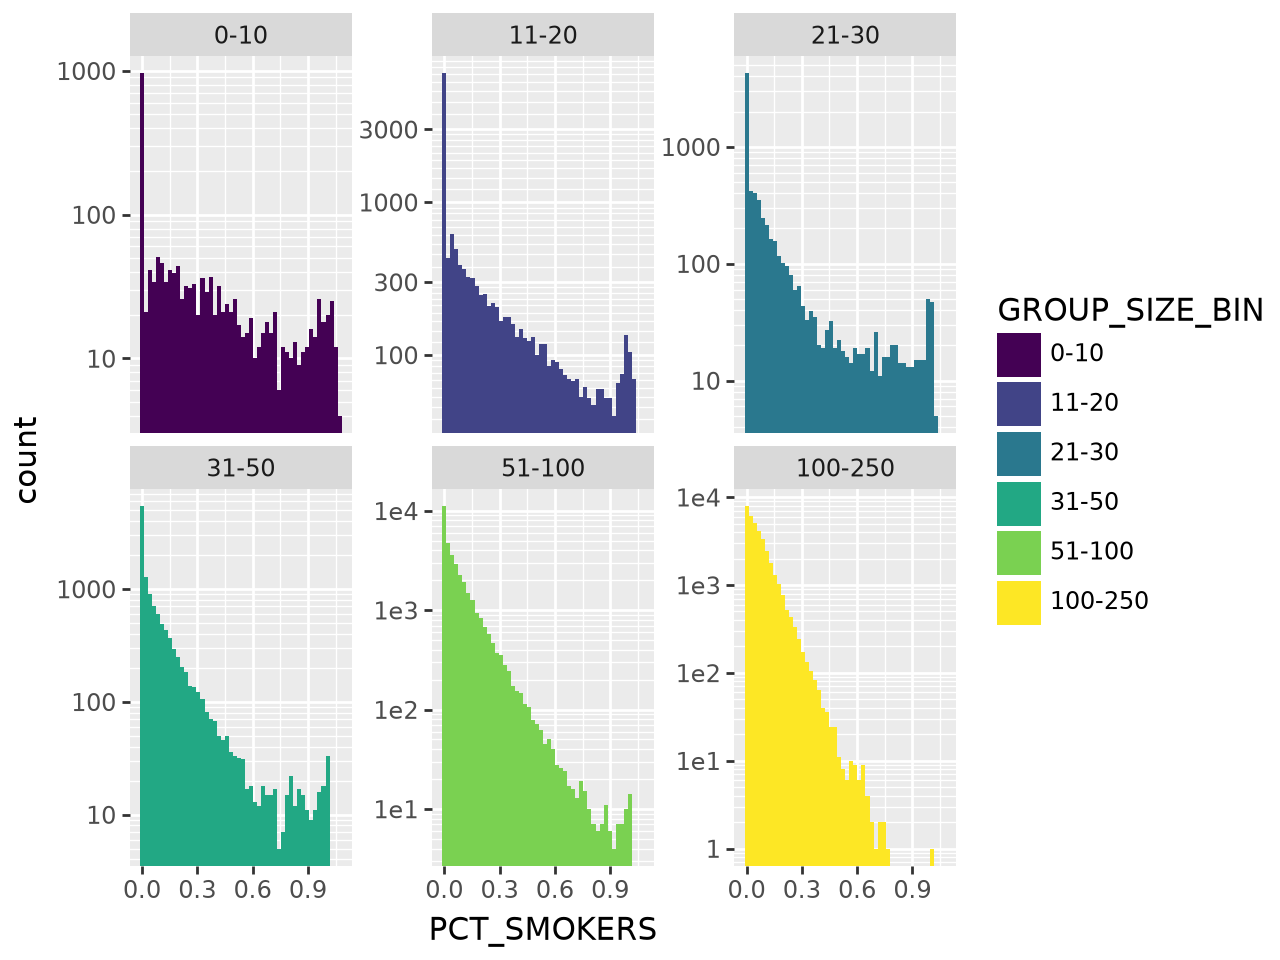

In [804]:
# percent of smokers in groups spans the interval 0-1, bunching up in different places
# over the interval 
(
    p9.ggplot(df_smoker_feature, p9.aes(x="PCT_SMOKERS", fill="GROUP_SIZE_BIN")) +
    p9.geom_histogram(bins=50) +
    p9.facet_wrap("GROUP_SIZE_BIN", scales="free_y") +
    p9.scale_y_continuous(trans="log10")
)

/home/mike/workspace/data-examples/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
/home/mike/workspace/data-examples/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
/home/mike/workspace/data-examples/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
/home/mike/workspace/data-examples/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
/home/mike/workspace/data-examples/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
/home/mike/workspace/data-examples/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
/home/mike/workspace/data-examples/.venv/lib/python3.12/site-packages/pandas/core/arrayl

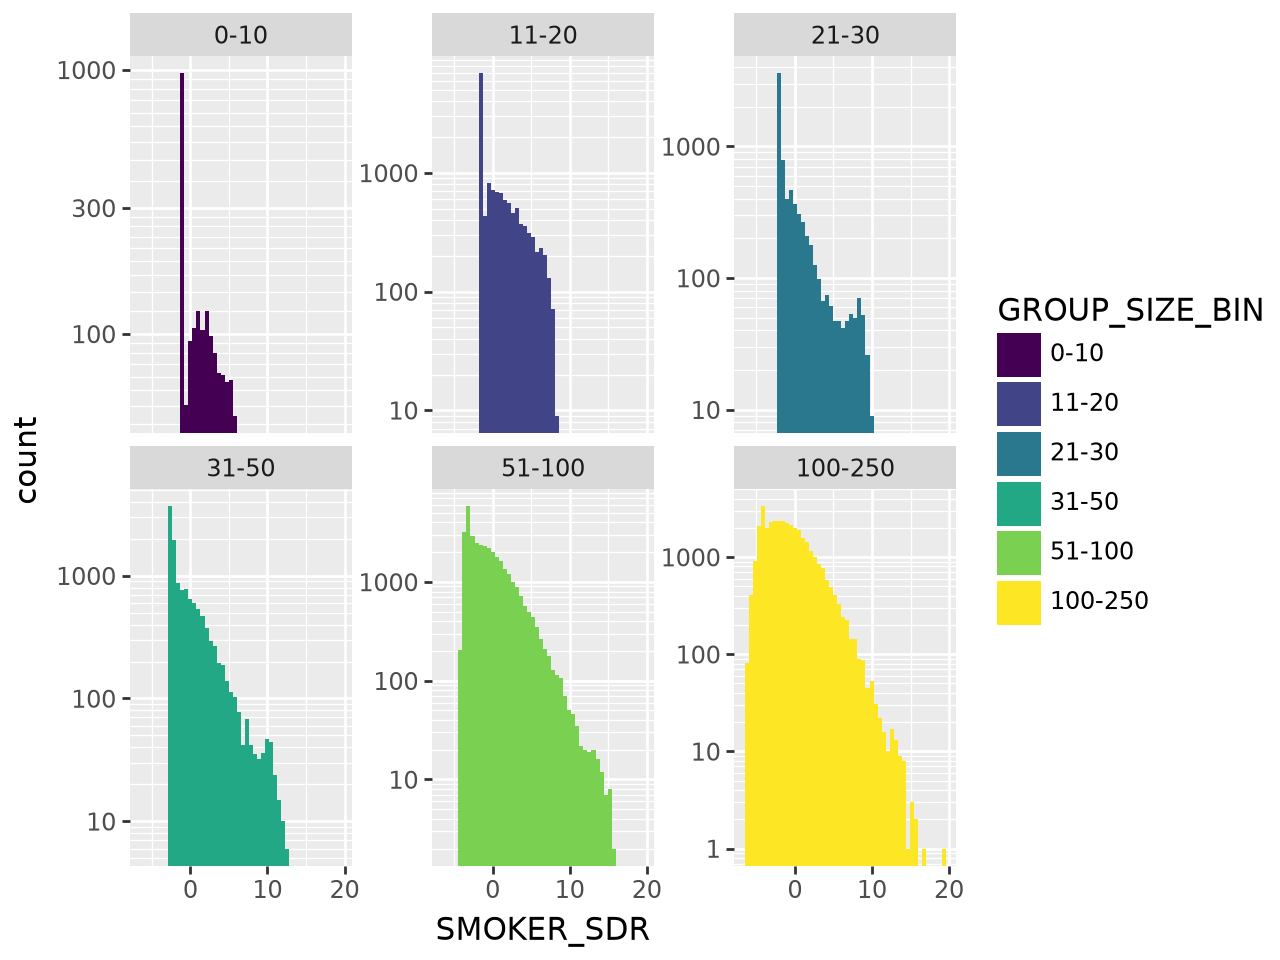

In [805]:
# SDRs span the interval -infinity,+infinity, and are centered around zero
(
    p9.ggplot(df_smoker_feature, p9.aes(x="SMOKER_SDR", fill="GROUP_SIZE_BIN")) +
    p9.geom_histogram(bins=50) +
    p9.facet_wrap("GROUP_SIZE_BIN", scales="free_y") +
    p9.scale_y_continuous(trans="log10")
)

### 

Suppose we want to examine the relationship between high numbers of smokers and poor mortality using A/E

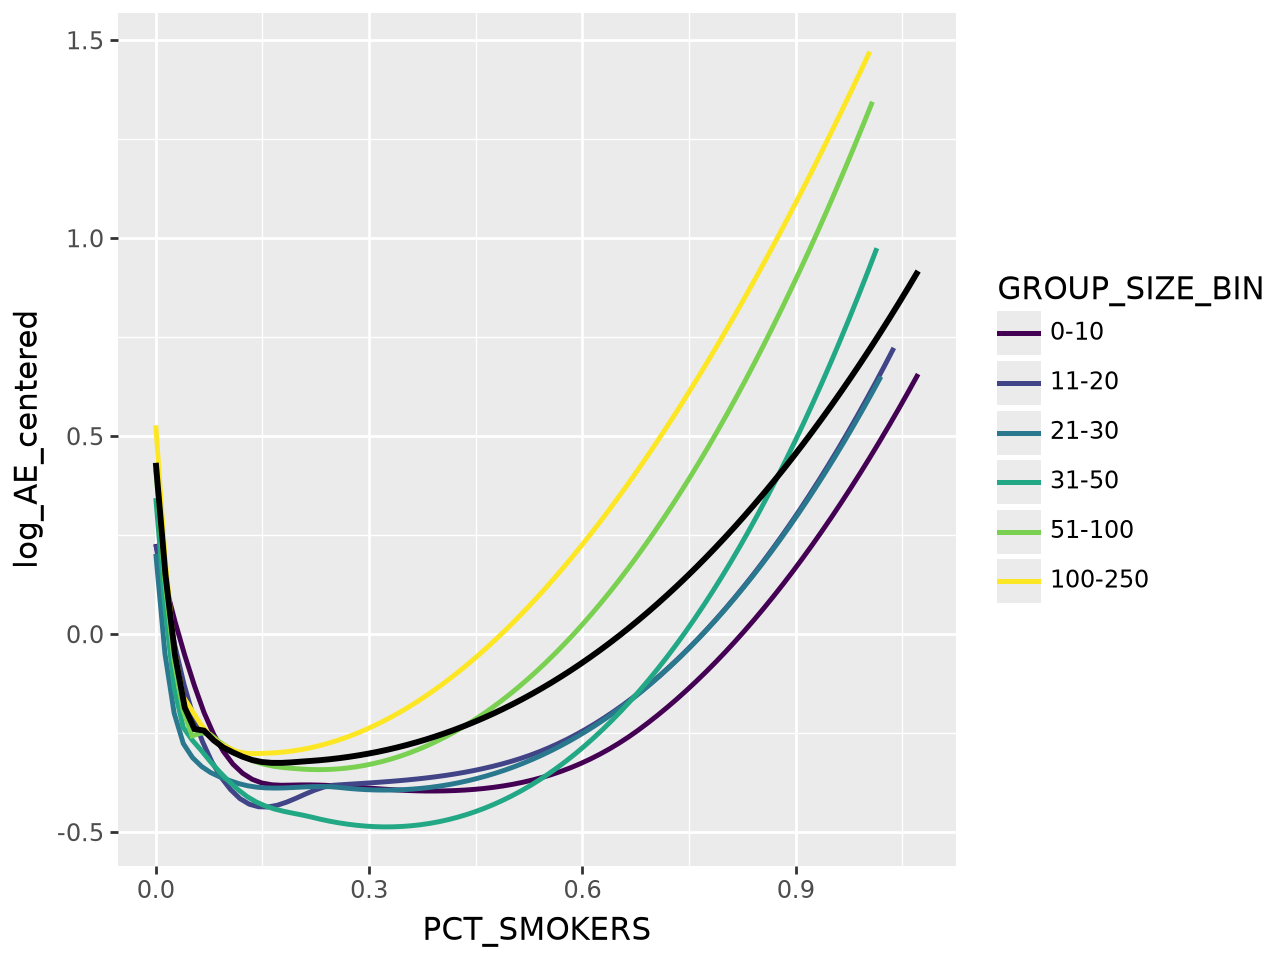

In [806]:
(
    p9.ggplot(
        df_smoker_feature,
        p9.aes(
            x="PCT_SMOKERS",
            y="log_AE_centered",
            color="GROUP_SIZE_BIN",
            weight="GROUP_SIZE",
        ),
    )
    + p9.stat_smooth(method="loess", se=False)
    + p9.stat_smooth(
        mapping=p9.aes(
            x="PCT_SMOKERS",
            y="log_AE_centered",
            group=1,
            weight="GROUP_SIZE",
        ),
        method="loess",
        se=False,
        color="black",
        size=1.2,
    )
    + p9.scale_y_continuous()
)

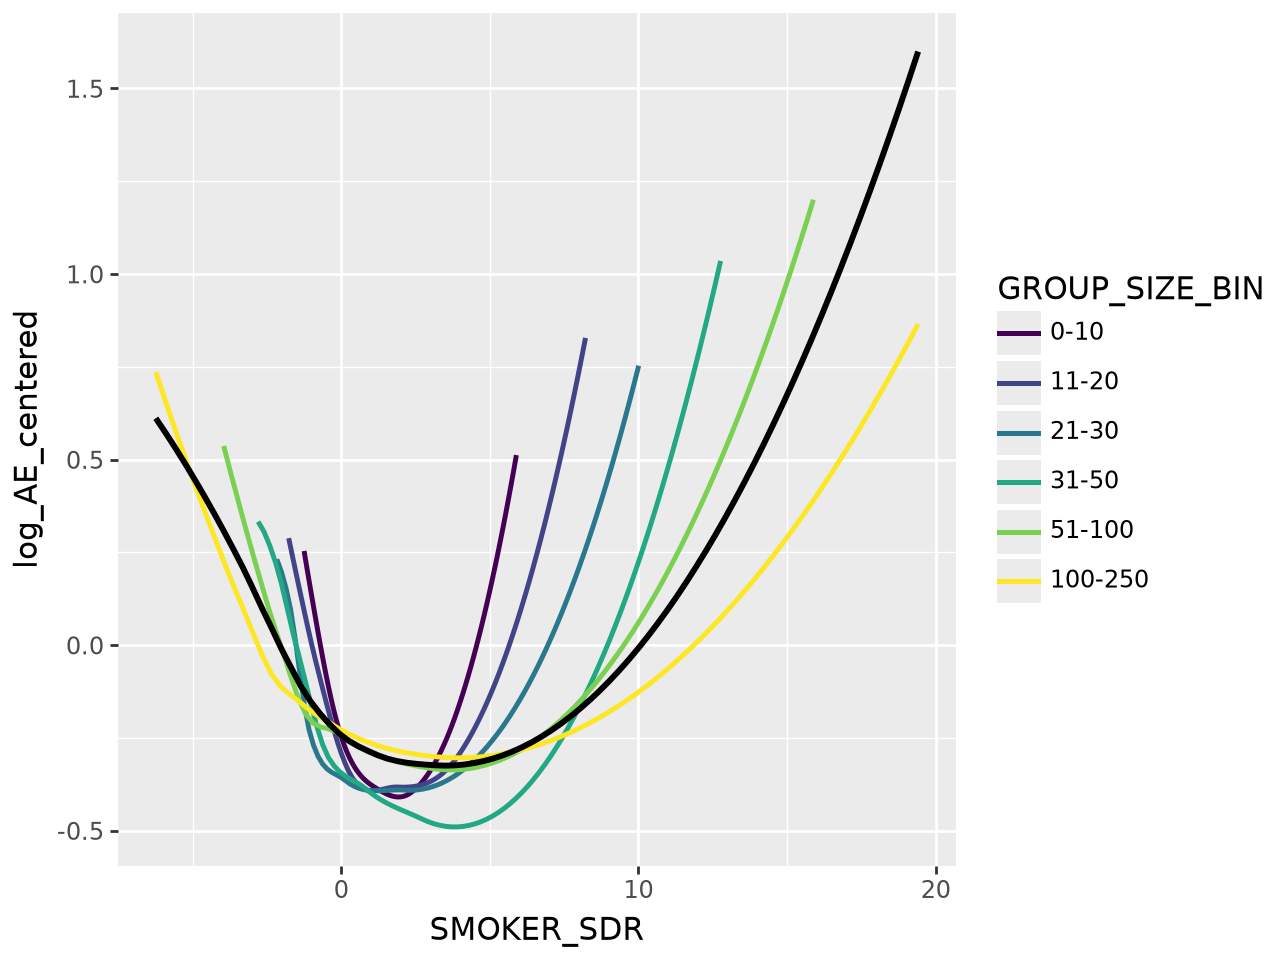

In [807]:
(
    p9.ggplot(
        df_smoker_feature,
        p9.aes(
            x="SMOKER_SDR",
            y="log_AE_centered",
            color="GROUP_SIZE_BIN",
            weight="GROUP_SIZE",
        ),
    )
    + p9.stat_smooth(method="loess", se=False)
    + p9.stat_smooth(
        mapping=p9.aes(
            x="SMOKER_SDR",
            y="log_AE_centered",
            group=1,
            weight="GROUP_SIZE",
        ),
        method="loess",
        se=False,
        color="black",
        size=1.2,
    )
    + p9.scale_y_continuous()
)

In [808]:
from src.lib.plotutil import plot_group_size_surface

fig_pct = plot_group_size_surface(
    df_smoker_feature,
    "PCT_SMOKERS",
    x_label="PCT_SMOKERS",
    title="Centered log(A/E) surface by PCT_SMOKERS and group-size bin",
)

fig_sdr = plot_group_size_surface(
    df_smoker_feature,
    "SMOKER_SDR",
    x_label="SMOKER_SDR",
    title="Centered log(A/E) surface by SDR and group-size bin",
)



/home/mike/workspace/data-examples/.venv/lib/python3.12/site-packages/statsmodels/nonparametric/smoothers_lowess.py:226: RuntimeWarning: invalid value encountered in divide


## Decision Tree Model

In [ ]:
from src.lib.tree import PoissonDecisionTree
import numpy as np
from scipy.special import gammaln


def _poisson_nll(y_true, y_pred):
    mu = np.clip(np.asarray(y_pred, dtype=float), 1e-12, None)
    y_true = np.asarray(y_true, dtype=float)
    return -np.sum(y_true * np.log(mu) - mu - gammaln(y_true + 1))


def run_better_count_sims(n_sims, variant="main_effects", sample_frac=0.1, seed=0):
    """Run repeated 10% samples and compare PCT vs SDR Poisson trees.

    variant options:
      - "main_effects": uses only PCT_SMOKERS / SMOKER_SDR
      - "with_group_size_interaction": uses GROUP_SIZE plus interaction constraints
    """
    if variant not in {"main_effects", "with_group_size_interaction"}:
        raise ValueError("variant must be 'main_effects' or 'with_group_size_interaction'.")

    n_sims = int(n_sims)
    better_count = 0
    better_wins = 0
    records = []

    for i in range(n_sims):
        sim_df = df_smoker_feature.sample(frac=sample_frac, random_state=seed + i)

        if variant == "main_effects":
            pct_features = ["PCT_SMOKERS", "CLAIM_COUNT", "EXPECTED_COUNT"]
            sdr_features = ["SMOKER_SDR", "CLAIM_COUNT", "EXPECTED_COUNT"]
            pct_model = PoissonDecisionTree(
                actual_col="CLAIM_COUNT",
                offset_col="EXPECTED_COUNT",
                params={"gamma": 1, "min_child_weight": 100},
                monotone_constraints={"PCT_SMOKERS": 1},
            )
            sdr_model = PoissonDecisionTree(
                actual_col="CLAIM_COUNT",
                offset_col="EXPECTED_COUNT",
                params={"gamma": 1, "min_child_weight": 100},
                monotone_constraints={"SMOKER_SDR": 1},
            )
        else:
            pct_features = ["PCT_SMOKERS", "GROUP_SIZE", "CLAIM_COUNT", "EXPECTED_COUNT"]
            sdr_features = ["SMOKER_SDR", "GROUP_SIZE", "CLAIM_COUNT", "EXPECTED_COUNT"]
            pct_model = PoissonDecisionTree(
                actual_col="CLAIM_COUNT",
                offset_col="EXPECTED_COUNT",
                params={"gamma": 1, "min_child_weight": 100},
                monotone_constraints={"PCT_SMOKERS": 1},
                interaction_constraints={("PCT_SMOKERS", "GROUP_SIZE"): 1},
            )
            sdr_model = PoissonDecisionTree(
                actual_col="CLAIM_COUNT",
                offset_col="EXPECTED_COUNT",
                params={"gamma": 1, "min_child_weight": 100},
                monotone_constraints={"SMOKER_SDR": 1},
                interaction_constraints={("SMOKER_SDR", "GROUP_SIZE"): 1},
            )

        pct_model.fit(sim_df[pct_features])
        sdr_model.fit(sim_df[sdr_features])

        y_true = sim_df["CLAIM_COUNT"].to_numpy(dtype=float)
        nll_pct = _poisson_nll(y_true, pct_model.predict(sim_df))
        nll_sdr = _poisson_nll(y_true, sdr_model.predict(sim_df))

        sdr_better = nll_sdr <= nll_pct
        better_wins += int(sdr_better)
        better_count += 1 if sdr_better else -1
        records.append(
            {
                "sim": i,
                "poisson_nll_pct": nll_pct,
                "poisson_nll_sdr": nll_sdr,
                "sdr_better": bool(sdr_better),
            }
        )

    better_pct = better_wins / n_sims if n_sims > 0 else np.nan

    return {
        "variant": variant,
        "n_sims": n_sims,
        "sample_frac": sample_frac,
        "better_count": better_count,
        "better_pct": better_pct,
        "results": records,
    }


(704, 0.852)

In [811]:
import random
seed_schedule = random.sample(range(1_000_000), 1)

sim_summary = run_better_count_sims(n_sims=1000, sample_frac=0.3, variant="main_effects", seed=seed_schedule[0])
sim_summary["better_count"], sim_summary["better_pct"]

(732, 0.866)

In [810]:
sim_summary = run_better_count_sims(n_sims=1000, sample_frac=0.3,  variant="with_group_size_interaction", seed=seed_schedule[0])
sim_summary["better_count"], sim_summary["better_pct"]

(150, 0.575)